Enter xmin:  1
Enter ymin:  1
Enter xmax:  5
Enter ymax:  5
Enter number of points:  3
Enter x1:  0
Enter y1:  0
Enter x2:  3
Enter y2:  3
Enter x3:  6
Enter y3:  4



Region Codes:
Point 1 ( 0.0 , 0.0 ) -> 0101
Point 2 ( 3.0 , 3.0 ) -> 0000
Point 3 ( 6.0 , 4.0 ) -> 0010


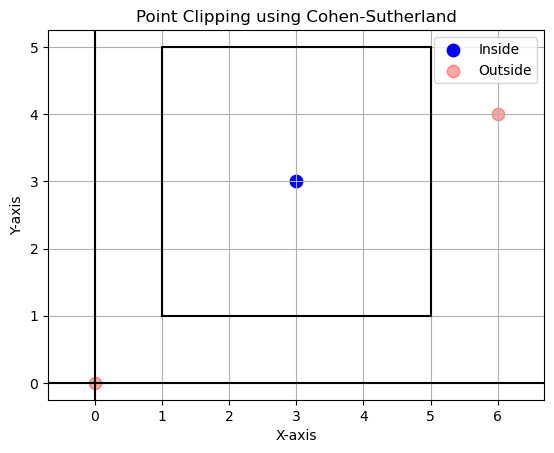

In [3]:
import matplotlib.pyplot as plt

xmin = float(input("Enter xmin: "))
ymin = float(input("Enter ymin: "))
xmax = float(input("Enter xmax: "))
ymax = float(input("Enter ymax: "))

n = int(input("Enter number of points: "))

points = []

for i in range(n):
    x = float(input("Enter x" + str(i + 1) + ": "))
    y = float(input("Enter y" + str(i + 1) + ": "))
    points.append((x, y))

inside_points = []
outside_points = []

print("\nRegion Codes:")

for i, (x, y) in enumerate(points):

    above = 0
    below = 0
    right = 0
    left = 0

    if y > ymax:
        above = 1

    if y < ymin:
        below = 1

    if x > xmax:
        right = 1

    if x < xmin:
        left = 1

    code = str(above) + str(below) + str(right) + str(left)

    print("Point", i + 1, "(", x, ",", y, ") ->", code)

    if code == "0000":
        inside_points.append((x, y))
    else:
        outside_points.append((x, y))

plt.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    color='black'
)

if inside_points:
    x_in = [p[0] for p in inside_points]
    y_in = [p[1] for p in inside_points]

    plt.scatter(
        x_in, y_in,
        color='blue',
        s=80,
        label="Inside"
    )

if outside_points:
    x_out = [p[0] for p in outside_points]
    y_out = [p[1] for p in outside_points]

    plt.scatter(
        x_out, y_out,
        color='red',
        alpha=0.35,
        s=80,
        label="Outside"
    )

plt.axhline(0, color='black')
plt.axvline(0, color='black')

plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Point Clipping using Cohen-Sutherland")
plt.grid(True)
plt.axis("equal")
plt.legend()

plt.show()

Enter xmin:  1
Enter ymin:  1
Enter xmax:  6
Enter ymax:  6
Enter number of lines:  2



Line 1


Enter x1:  0
Enter y1:  0
Enter x2:  4
Enter y2:  4



Line 2


Enter x1:  5
Enter y1:  5
Enter x2:  8
Enter y2:  0



Line 1
Point 1 code: 0101
Point 2 code: 0000
Line Accepted

Line 2
Point 1 code: 0000
Point 2 code: 0110
Line Accepted


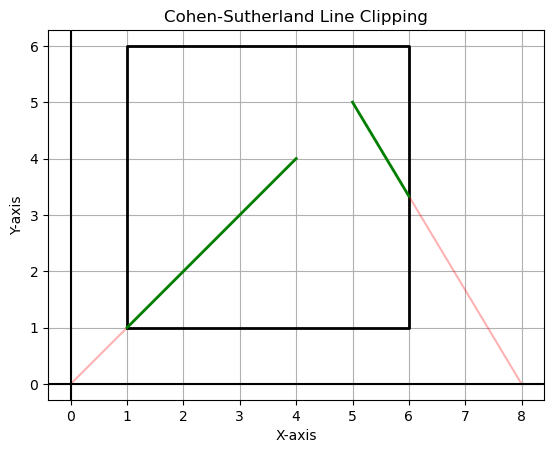

In [7]:
import matplotlib.pyplot as plt

xmin = float(input("Enter xmin: "))
ymin = float(input("Enter ymin: "))
xmax = float(input("Enter xmax: "))
ymax = float(input("Enter ymax: "))

n = int(input("Enter number of lines: "))

def region_code(x, y):

    above = 0
    below = 0
    right = 0
    left = 0

    if y > ymax:
        above = 1
    if y < ymin:
        below = 1
    if x > xmax:
        right = 1
    if x < xmin:
        left = 1
    return (above, below, right, left)


def clip_line(x1, y1, x2, y2):

    code1 = region_code(x1, y1)
    code2 = region_code(x2, y2)

    while True:

        c1 = code1[0] * 8 + code1[1] * 4 + code1[2] * 2 + code1[3]
        c2 = code2[0] * 8 + code2[1] * 4 + code2[2] * 2 + code2[3]

        if c1 == 0 and c2 == 0:
            return x1, y1, x2, y2

        if c1 & c2:
            return None

        if c1 != 0:
            code = code1
        else:
            code = code2

        if code[0] == 1:         
            x = x1 + (x2 - x1) * (ymax - y1) / (y2 - y1)
            y = ymax

        elif code[1] == 1:        
            x = x1 + (x2 - x1) * (ymin - y1) / (y2 - y1)
            y = ymin

        elif code[2] == 1:      
            y = y1 + (y2 - y1) * (xmax - x1) / (x2 - x1)
            x = xmax

        else:                   
            y = y1 + (y2 - y1) * (xmin - x1) / (x2 - x1)
            x = xmin

        if c1 != 0:
            x1 = x
            y1 = y
            code1 = region_code(x1, y1)
        else:
            x2 = x
            y2 = y
            code2 = region_code(x2, y2)

lines = []

for i in range(n):

    print("\nLine", i + 1)

    x1 = float(input("Enter x1: "))
    y1 = float(input("Enter y1: "))

    x2 = float(input("Enter x2: "))
    y2 = float(input("Enter y2: "))

    lines.append((x1, y1, x2, y2))


plt.plot(
    [xmin, xmax, xmax, xmin, xmin],
    [ymin, ymin, ymax, ymax, ymin],
    color='black',
    linewidth=2
)


for i, (x1, y1, x2, y2) in enumerate(lines):

    code1 = region_code(x1, y1)
    code2 = region_code(x2, y2)

    print("\nLine", i + 1)

    print("Point 1 code:",
          str(code1[0]) + str(code1[1]) +
          str(code1[2]) + str(code1[3]))

    print("Point 2 code:",
          str(code2[0]) + str(code2[1]) +
          str(code2[2]) + str(code2[3]))

    plt.plot(
        [x1, x2],
        [y1, y2],
        color='red',
        alpha=0.3
    )

    result = clip_line(x1, y1, x2, y2)

    if result is not None:

        x1c, y1c, x2c, y2c = result

        plt.plot(
            [x1c, x2c],
            [y1c, y2c],
            color='blue',
            linewidth=2
        )

        print("Line Accepted")

    else:
        print("Line Rejected")

plt.axhline(0, color='black')
plt.axvline(0, color='black')

plt.xlabel("X-axis")
plt.ylabel("Y-axis")
plt.title("Cohen-Sutherland Line Clipping")

plt.grid(True)

plt.axis("equal")

plt.show()